# 06_Cutoff_Strategy — Évaluation finale sur le test et stratégie de seuils

**Projet :** Credit Risk Scorecard · **Phase 4** — sous-ensembles 4b et 4c · Données : Home Credit Default Risk (Kaggle).

- Les calculs sont faits par `scripts/evaluate_models.py` (seul script qui lit le test, lectures journalisées, D15) puis `scripts/build_cutoff_strategy.py` ; ce notebook **relit leurs sorties** (`output/tables/`, `models/all_scores.parquet`) et **n'ouvre pas le test** dans la base.
- Seuils **choisis sur la validation**, **évalués sur le test**. Score élevé = risque faible.
- Figures écrites : `output/06_*.png`.

In [1]:
# --- Setup : vérification du répertoire de travail, connexion DuckDB en lecture seule ---
import os
import sys
from pathlib import Path

cwd = Path.cwd()
# Jupyter / VS Code lancent le noyau dans notebooks/ : on remonte d'un niveau si c'est le cas.
if cwd.name == "notebooks" and (cwd.parent / "scripts" / "config.py").is_file():
    os.chdir(cwd.parent)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name != "credit-risk-scorecard" or not (PROJECT_ROOT / "scripts" / "config.py").is_file():
    raise RuntimeError(
        f"Répertoire de travail inattendu : {PROJECT_ROOT}. "
        "Lancer le notebook depuis la racine credit-risk-scorecard/ (ou depuis notebooks/)."
    )
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

import hashlib

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from config import DB_PATH, FIGURES_DIR

if not DB_PATH.exists():
    raise FileNotFoundError(f"{DB_PATH} introuvable.")
con = duckdb.connect(str(DB_PATH), read_only=True)

# Style des figures : identique aux notebooks 00 à 05
BLUE, INK, INK2, GRID, GREY = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#a3a29d"
RED = "#c8553d"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9,
})
print("Racine :", PROJECT_ROOT.name)
print(f"Python {sys.version.split()[0]} · duckdb {duckdb.__version__} · pandas {pd.__version__} · matplotlib {matplotlib.__version__}")

Racine : credit-risk-scorecard
Python 3.13.15 · duckdb 1.5.5 · pandas 3.0.6 · matplotlib 3.11.2


In [2]:
# --- Sorties des scripts 4b et 4c ---
import json

from sklearn.metrics import roc_curve

import build_cutoff_strategy as bcs
import evaluate_models as em

paths = [em.FINAL_COMPARISON_CSV, em.EVAL_JSON, em.CALIBRATION_CSV, em.PSI_CSV, em.FAIRNESS_CSV, em.REFUSAL_CSV,
         em.ALL_SCORES, bcs.CUTOFF_SCENARIOS_CSV, bcs.SCORE_DECILES_CSV, bcs.CUTOFF_JSON]
missing = [p.name for p in paths if not p.exists()]
if missing:
    raise FileNotFoundError(f"Absents : {missing}. Lancer scripts/evaluate_models.py puis scripts/build_cutoff_strategy.py.")
ev = json.loads(em.EVAL_JSON.read_text(encoding="utf-8"))
st = json.loads(bcs.CUTOFF_JSON.read_text(encoding="utf-8"))
comp = pd.read_csv(em.FINAL_COMPARISON_CSV)
scores = pd.read_parquet(em.ALL_SCORES)
test = scores[scores["split"].eq("test")]
if ev["dry_run"]:
    display(Markdown("**Attention : sorties de répétition (--dry-run), le test n'a pas été ouvert.**"))
else:
    o = ev["test_opening"]
    print(f"Dernière lecture du test : {o['timestamp_utc']} · {o['n_rows']:,} demandes · empreinte conforme : {o['fingerprint_match']}")
NAMES = {"scorecard": "Grille", "lgbm": "LightGBM", "lgbm_no_ext": "LightGBM sans EXT_SOURCE"}

Dernière lecture du test : 2026-10-08T09:48:02Z · 46,127 demandes · empreinte conforme : True


## 1. Comparaison finale et intervalles de confiance

Grille : AUC et KS sur le score entier, Brier sur la PD du logit. IC à 95 % : bootstrap apparié du test (1 000 rééchantillonnages, graine 42).

In [3]:
fmt = {c: "{:.4f}" for c in ("auc", "gini", "ks", "brier", "mean_pd", "default_rate")}
display(comp.assign(model=comp["model"].map(NAMES)).style.format(fmt | {"n": "{:,}"}).hide(axis="index"))
b = ev["bootstrap"]
ci = pd.DataFrame([{"indicateur": k, "estimation": b[k]["estimate"], "IC bas": b[k]["low"], "IC haut": b[k]["high"]}
                   for k in ("scorecard_auc", "scorecard_gini", "lgbm_auc", "lgbm_gini", "auc_diff_lgbm_minus_scorecard")])
display(ci.style.format({c: "{:.4f}" for c in ("estimation", "IC bas", "IC haut")}).hide(axis="index"))
print(f"Part des rééchantillonnages où LightGBM bat la grille : {b['share_resamples_lgbm_better']:.1%}")

model,split,n,auc,gini,ks,brier,mean_pd,default_rate
Grille,train,"215,257",0.7544,0.5087,0.3810,0.0682,0.0807,0.0807
Grille,valid,"46,127",0.7529,0.5059,0.3808,0.0683,0.0807,0.0807
Grille,test,"46,127",0.7518,0.5035,0.3762,0.0684,0.0805,0.0807
LightGBM,train,"215,257",0.8808,0.7615,0.5948,0.0568,0.0806,0.0807
LightGBM,valid,"46,127",0.7851,0.5702,0.4322,0.0659,0.0797,0.0807
LightGBM,test,"46,127",0.7883,0.5766,0.4384,0.0659,0.0796,0.0807
LightGBM sans EXT_SOURCE,train,"215,257",0.8490,0.6981,0.5346,0.0609,0.0807,0.0807
LightGBM sans EXT_SOURCE,valid,"46,127",0.7617,0.5234,0.3865,0.0677,0.0802,0.0807
LightGBM sans EXT_SOURCE,test,"46,127",0.7598,0.5195,0.3887,0.0679,0.0799,0.0807


indicateur,estimation,IC bas,IC haut
scorecard_auc,0.7518,0.7437,0.7598
scorecard_gini,0.5035,0.4874,0.5196
lgbm_auc,0.7883,0.7809,0.7960
lgbm_gini,0.5766,0.5618,0.5921
auc_diff_lgbm_minus_scorecard,0.0365,0.0319,0.0408


Part des rééchantillonnages où LightGBM bat la grille : 100.0%


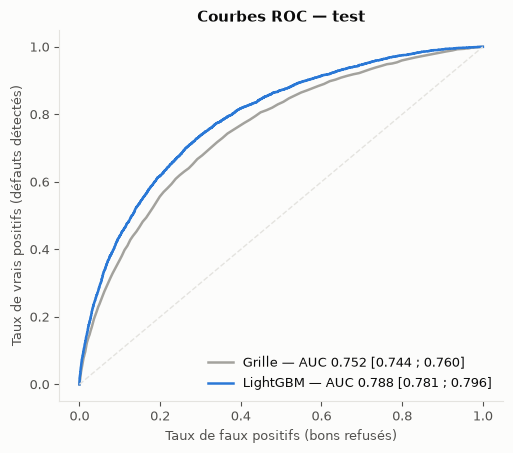

In [4]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for lab, risk, col in (("Grille", -test["score"], GREY), ("LightGBM", test["pd_lgbm"], BLUE)):
    fpr, tpr, _ = roc_curve(test["TARGET"], risk)
    key = "scorecard_auc" if lab == "Grille" else "lgbm_auc"
    ax.plot(fpr, tpr, color=col, lw=1.8, label=f"{lab} — AUC {b[key]['estimate']:.3f} [{b[key]['low']:.3f} ; {b[key]['high']:.3f}]")
ax.plot([0, 1], [0, 1], color=GRID, ls="--", lw=1)
ax.set_xlabel("Taux de faux positifs (bons refusés)")
ax.set_ylabel("Taux de vrais positifs (défauts détectés)")
ax.set_title("Courbes ROC — test")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_roc_test.png", dpi=150)
plt.show()

## 2. Calibration (test)

PD moyenne prédite vs taux de défaut observé par décile de PD. Critère de mauvaise calibration : écart moyen > 1 pt ou écart max > 3 pt ; la régression isotone de contrôle est ajustée sur la validation, jamais sur le test.

,mean_pd,default_rate,brier,mean_abs_decile_gap,max_abs_decile_gap,miscalibrated,isotonic_valid_brier_test
Grille,0.0805,0.0807,0.0684,0.0020,0.0040,False,0.0685
LightGBM,0.0796,0.0807,0.0659,0.0025,0.0093,False,0.0660


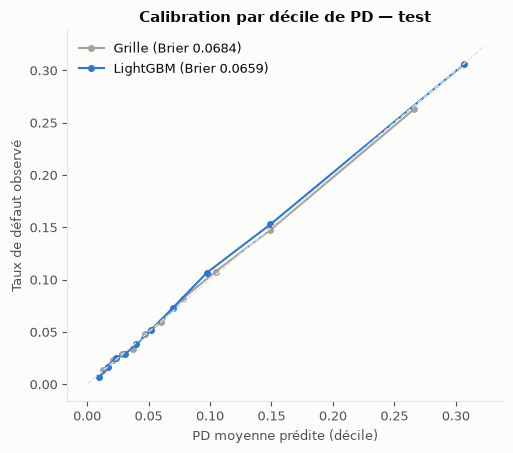

In [5]:
cal = pd.read_csv(em.CALIBRATION_CSV)
cv = pd.DataFrame({NAMES[k]: ev["calibration"][k] for k in ("scorecard", "lgbm")}).T
display(cv[["mean_pd", "default_rate", "brier", "mean_abs_decile_gap", "max_abs_decile_gap", "miscalibrated", "isotonic_valid_brier_test"]]
        .style.format({c: "{:.4f}" for c in ("mean_pd", "default_rate", "brier", "mean_abs_decile_gap", "max_abs_decile_gap", "isotonic_valid_brier_test")}))
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for m, col in (("scorecard", GREY), ("lgbm", BLUE)):
    d = cal[cal["model"].eq(m)]
    ax.plot(d["pd_mean"], d["observed_rate"], "o-", color=col, ms=4, label=f"{NAMES[m]} (Brier {ev['calibration'][m]['brier']:.4f})")
lim = cal[["pd_mean", "observed_rate"]].max().max() * 1.05
ax.plot([0, lim], [0, lim], color=GRID, ls="--", lw=1)
ax.set_xlabel("PD moyenne prédite (décile)")
ax.set_ylabel("Taux de défaut observé")
ax.set_title("Calibration par décile de PD — test")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_calibration.png", dpi=150)
plt.show()

## 3. Stabilité (PSI train → test)

Score : 10 tranches = déciles du score du train. Variables : classes WoE de la grille (stabilité caractéristique). Seuils : 0,10 (à surveiller) et 0,25 (instable).

level,name,n_bins,psi,psi_train_valid,flag
variable,ORGANIZATION_TYPE,8,0.00056,0.00022,stable
variable,APP_EXT_SOURCE_MEAN,15,0.00042,0.00031,stable
variable,CC_MEAN_UTILIZATION,3,0.00027,0.00001,stable
variable,PREV_MEAN_CREDIT_APPLICATION_RATIO,12,0.00025,0.00010,stable
variable,BUR_YEARS_SINCE_LAST_CREDIT,8,0.00021,0.00008,stable
variable,INS_SHARE_LATE,8,0.00020,0.00020,stable
variable,EXT_SOURCE_3,11,0.00018,0.00025,stable
variable,EXT_SOURCE_1,6,0.00016,0.00004,stable


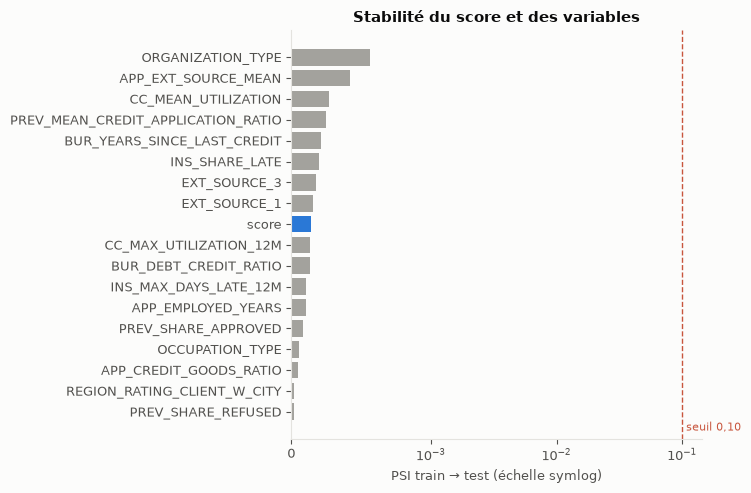

In [6]:
psi = pd.read_csv(em.PSI_CSV)
display(psi.sort_values("psi", ascending=False).head(8).style.format({"psi": "{:.5f}", "psi_train_valid": "{:.5f}"}).hide(axis="index"))
p = psi.sort_values("psi")
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(p["name"], p["psi"], color=[BLUE if n == "score" else GREY for n in p["name"]])
ax.axvline(em.PSI_MODERATE, color=RED, ls="--", lw=1)
ax.text(em.PSI_MODERATE, -0.9, " seuil 0,10", color=RED, fontsize=8)
ax.set_xscale("symlog", linthresh=1e-3)
ax.set_xlabel("PSI train → test (échelle symlog)")
ax.set_title("Stabilité du score et des variables")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_psi.png", dpi=150)
plt.show()

## 4. Équité — `CODE_GENDER` (exclue du modèle)

Seuil du scénario recommandé. Le groupe `XNA` (effectif minime) est ignoré.

group,n,default_rate,mean_score,mean_pd_scorecard,mean_pd_lgbm,auc_scorecard,auc_lgbm,cutoff,approval_rate,approval_rate_goods,approval_rate_bads,bad_rate_accepted
F,"30,429",0.0696,570.9,0.0741,0.0721,0.7500,0.7847,563,0.6418,0.6683,0.2880,0.0312
M,"15,698",0.1023,563.4,0.0929,0.0941,0.7423,0.7844,563,0.5269,0.5623,0.2161,0.0420


XNA : 0 au test (4 au total) · ratio d'acceptation M/F : 0.821 · parmi les bons clients : 0.841


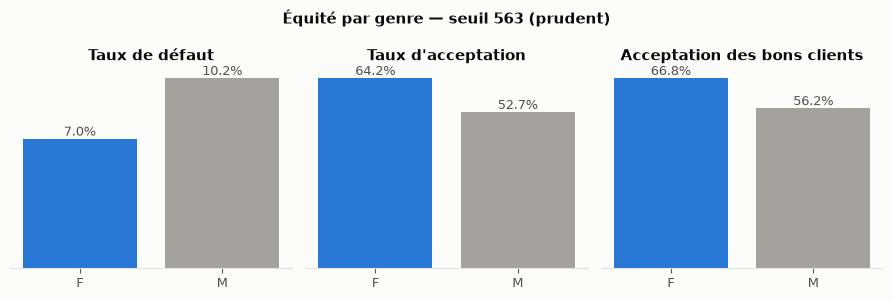

In [7]:
fair = pd.read_csv(em.FAIRNESS_CSV)
fa = ev["fairness"]
display(fair.drop(columns=["scenario"]).style.format({c: "{:.4f}" for c in fair.columns if fair[c].dtype == float} | {"mean_score": "{:.1f}", "n": "{:,}"}).hide(axis="index"))
print(f"XNA : {fa['xna_count_test']} au test ({fa['xna_count_all']} au total) · ratio d'acceptation M/F : "
      f"{1 / fa['approval_ratio_f_over_m']:.3f} · parmi les bons clients : {1 / fa['approval_ratio_goods_f_over_m']:.3f}")
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, col, lab in zip(axes, ("default_rate", "approval_rate", "approval_rate_goods"),
                        ("Taux de défaut", "Taux d'acceptation", "Acceptation des bons clients")):
    ax.bar(fair["group"], fair[col], color=[BLUE, GREY])
    for x, v in enumerate(fair[col]):
        ax.text(x, v, f"{v:.1%}", ha="center", va="bottom", color=INK2)
    ax.set_title(lab)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
fig.suptitle(f"Équité par genre — seuil {fa['cutoff']} ({fa['scenario']})", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_fairness.png", dpi=150)
plt.show()

## 5. Motifs de refus (grille)

Pour chaque demande : les 3 variables au plus grand manque de points par rapport au maximum de la variable. Distribution parmi les refusés du test (scénario recommandé).

variable,scenario,cutoff,n_reason1_refused,n_top3_refused,n_reason1_all_test,pct_reason1_refused,pct_top3_refused,pct_reason1_all_test,max_points
APP_EXT_SOURCE_MEAN,prudent,563,18233,18287,40339,99.5%,99.8%,87.5%,65
CC_MAX_UTILIZATION_12M,prudent,563,57,2317,399,0.3%,12.6%,0.9%,37
APP_CREDIT_GOODS_RATIO,prudent,563,22,4158,886,0.1%,22.7%,1.9%,37
INS_MAX_DAYS_LATE_12M,prudent,563,8,1600,130,0.0%,8.7%,0.3%,35
APP_EMPLOYED_YEARS,prudent,563,4,8114,1299,0.0%,44.3%,2.8%,40
REGION_RATING_CLIENT_W_CITY,prudent,563,1,3716,907,0.0%,20.3%,2.0%,40
INS_SHARE_LATE,prudent,563,1,1704,328,0.0%,9.3%,0.7%,37
EXT_SOURCE_3,prudent,563,0,6145,410,0.0%,33.5%,0.9%,39
PREV_MEAN_CREDIT_APPLICATION_RATIO,prudent,563,0,3292,570,0.0%,18.0%,1.2%,38
BUR_DEBT_CREDIT_RATIO,prudent,563,0,2870,365,0.0%,15.7%,0.8%,39


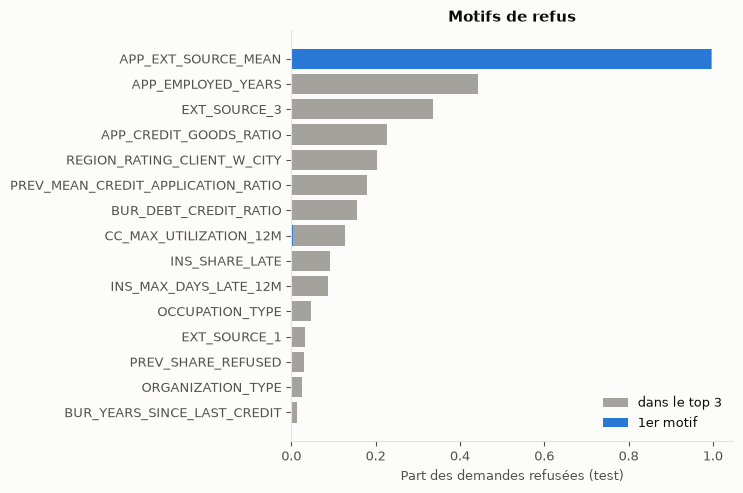

In [8]:
rr = pd.read_csv(em.REFUSAL_CSV)
display(rr.head(10).style.format({c: "{:.1%}" for c in rr.columns if c.startswith("pct_")}).hide(axis="index"))
r = rr.sort_values("pct_top3_refused")
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(r["variable"], r["pct_top3_refused"], color=GREY, label="dans le top 3")
ax.barh(r["variable"], r["pct_reason1_refused"], color=BLUE, label="1er motif")
ax.set_xlabel("Part des demandes refusées (test)")
ax.set_title("Motifs de refus")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_refusal_reasons.png", dpi=150)
plt.show()

## 6. Tableau des déciles de score (test)

Bornes = déciles du score du train ; du meilleur score (décile 10) au plus risqué. Cumuls : on accepte du haut vers le bas.

decile,n,defaults,score_min,score_max,pd_mean,default_rate,cum_approval_rate,cum_bad_rate_accepted
10,"4,964",71,602,647,1.34%,1.43%,10.8%,1.43%
9,"4,749",113,592,601,2.19%,2.38%,21.1%,1.89%
8,"4,163",118,585,591,2.91%,2.83%,30.1%,2.18%
7,"5,098",179,577,584,3.76%,3.51%,41.1%,2.54%
6,"4,462",218,570,576,4.85%,4.89%,50.8%,2.98%
5,"4,365",258,563,569,6.14%,5.91%,60.3%,3.44%
4,"4,950",418,554,562,7.94%,8.44%,71.0%,4.20%
3,"4,522",510,544,553,10.75%,11.28%,80.8%,5.06%
2,"4,425",665,531,543,15.21%,15.03%,90.4%,6.12%
1,"4,429",1174,468,530,26.91%,26.51%,100.0%,8.07%


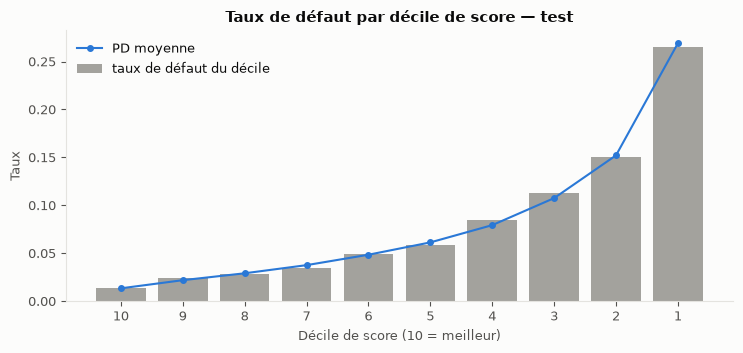

In [9]:
dec = pd.read_csv(bcs.SCORE_DECILES_CSV)
dt = dec[dec["split"].eq("test")].drop(columns="split")
display(dt.style.format({"pd_mean": "{:.2%}", "default_rate": "{:.2%}", "cum_approval_rate": "{:.1%}",
                         "cum_bad_rate_accepted": "{:.2%}", "n": "{:,}"}).hide(axis="index"))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(dt["decile"].astype(str), dt["default_rate"], color=GREY, label="taux de défaut du décile")
ax.plot(dt["decile"].astype(str), dt["pd_mean"], "o-", color=BLUE, ms=4, label="PD moyenne")
ax.set_xlabel("Décile de score (10 = meilleur)")
ax.set_ylabel("Taux")
ax.set_title("Taux de défaut par décile de score — test")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_score_deciles.png", dpi=150)
plt.show()

## 7. Scénarios de seuil et perte attendue

Cibles d'acceptation 60 / 75 / 85 % sur la validation ; zone de revue ± 10 points (PDO / 2). EL = PD × LGD × EAD (EAD = `AMT_CREDIT`, LGD 45 %).

scenario,split,cutoff,approval_rate,bad_rate_accepted,good_refused_n,good_refused_pct,el_accepted,el_avoided,el_avoided_pct,zone_review_pct,marginal_bad_rate,breakeven_margin
prudent,valid,563,60.1%,3.48%,"15,647",36.9%,"272,257,998","638,653,221",70.1%,25.7%,—,—
prudent,test,563,60.3%,3.44%,"15,559",36.7%,"272,364,036","632,551,500",69.9%,25.4%,—,—
equilibre,valid,550,75.2%,4.48%,"9,253",21.8%,"424,909,698","486,001,521",53.4%,20.5%,8.45%,4.2%
equilibre,test,550,75.3%,4.49%,"9,249",21.8%,"422,787,359","482,128,177",53.3%,20.2%,8.72%,4.2%
croissance,valid,539,85.1%,5.50%,"5,326",12.6%,"558,406,356","352,504,864",38.7%,15.1%,13.25%,6.3%
croissance,test,539,85.0%,5.43%,"5,342",12.6%,"554,717,733","350,197,802",38.7%,15.4%,12.73%,6.4%


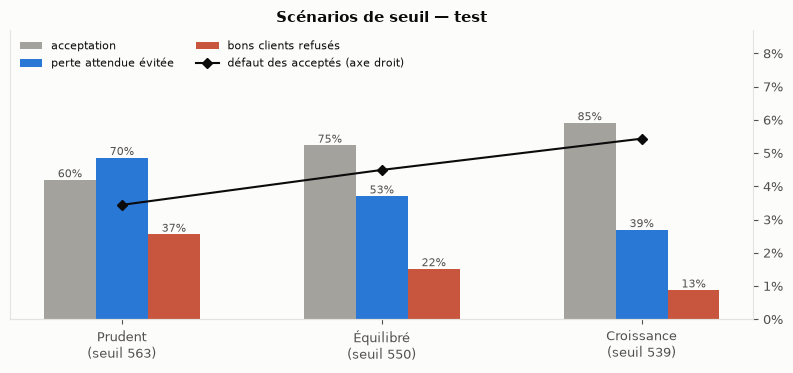

In [10]:
scen = pd.read_csv(bcs.CUTOFF_SCENARIOS_CSV)
base = scen[scen["lgd"].eq(st["lgd_base"])]
cols = ["scenario", "split", "cutoff", "approval_rate", "bad_rate_accepted", "good_refused_n", "good_refused_pct",
        "el_accepted", "el_avoided", "el_avoided_pct", "zone_review_pct", "marginal_bad_rate", "breakeven_margin"]
display(base[cols].style.format({c: "{:.1%}" for c in ("approval_rate", "good_refused_pct", "el_avoided_pct", "zone_review_pct", "breakeven_margin")}
                                | {c: "{:.2%}" for c in ("bad_rate_accepted", "marginal_bad_rate")}
                                | {"el_accepted": "{:,.0f}", "el_avoided": "{:,.0f}", "good_refused_n": "{:,}"}, na_rep="—").hide(axis="index"))
bt = base[base["split"].eq("test")].set_index("scenario")
lab = [bcs.SCENARIO_LABELS[s] + f"\n(seuil {bt.loc[s, 'cutoff']})" for s in bt.index]
x = np.arange(len(bt))
fig, ax = plt.subplots(figsize=(8, 3.8))
w = 0.2
for i, (col, name, c) in enumerate((("approval_rate", "acceptation", GREY), ("el_avoided_pct", "perte attendue évitée", BLUE),
                                   ("good_refused_pct", "bons clients refusés", RED))):
    ax.bar(x + (i - 1) * w, bt[col], w, color=c, label=name)
    for xi, v in zip(x + (i - 1) * w, bt[col]):
        ax.text(xi, v, f"{v:.0%}", ha="center", va="bottom", fontsize=8, color=INK2)
ax2 = ax.twinx()
ax2.plot(x, bt["bad_rate_accepted"], "D-", color=INK, ms=5, label="défaut des acceptés (axe droit)")
ax2.set_ylim(0, bt["bad_rate_accepted"].max() * 1.6)
ax2.spines["right"].set_visible(True)
ax2.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.set_xticks(x, lab)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_title("Scénarios de seuil — test")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, fontsize=8, loc="upper left", ncol=2)
ax.set_ylim(0, 1.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_scenarios.png", dpi=150)
plt.show()

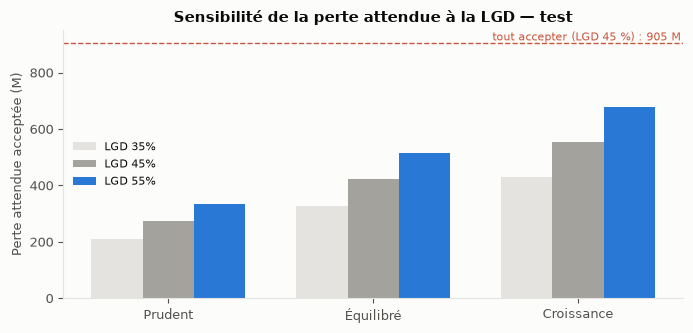

In [11]:
sens = scen[scen["split"].eq("test")].pivot(index="scenario", columns="lgd", values="el_accepted").loc[list(st["cutoffs"])]
fig, ax = plt.subplots(figsize=(7, 3.4))
w = 0.25
for i, lgd in enumerate(sens.columns):
    ax.bar(np.arange(len(sens)) + (i - 1) * w, sens[lgd] / 1e6, w, color=[GRID, GREY, BLUE][i], label=f"LGD {lgd:.0%}")
aa = st["approve_all_test"]["el_all"] / 1e6
ax.axhline(aa, color=RED, ls="--", lw=1)
ax.text(len(sens) - 0.5, aa, f"tout accepter (LGD 45 %) : {aa:,.0f} M", color=RED, ha="right", va="bottom", fontsize=8)
ax.set_xticks(np.arange(len(sens)), [bcs.SCENARIO_LABELS[s] for s in sens.index])
ax.set_ylabel("Perte attendue acceptée (M)")
ax.set_title("Sensibilité de la perte attendue à la LGD — test")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_el_sensitivity.png", dpi=150)
plt.show()

## 8. Recommandation

Règle fixée sur la validation avant lecture des résultats du test : maximiser « part de la perte attendue évitée − part des bons clients refusés ». Le texte ci-dessous est construit à partir des sorties.

In [12]:
reco = st["recommended"]
r, aa = st["recommended_test"], st["approve_all_test"]
order = list(st["cutoffs"])
nxt = order[order.index(reco) + 1] if order.index(reco) + 1 < len(order) else None
crit = " ; ".join(f"{bcs.SCENARIO_LABELS[k]} {v:.4f}" for k, v in st["recommendation_criterion_valid"].items())
txt = (f"**Scénario recommandé : {bcs.SCENARIO_LABELS[reco]} (seuil {st['cutoffs'][reco]['cutoff']}).** "
       f"Critère sur la validation : {crit}. Sur le test : acceptation {r['approval_rate']:.1%}, défaut des acceptés "
       f"{r['bad_rate_accepted']:.2%} contre {aa['bad_rate_accepted']:.2%} sans seuil, {r['el_avoided_pct']:.1%} de la perte "
       f"attendue évitée ({r['el_avoided'] / 1e6:,.0f} M à LGD 45 %) pour {r['good_refused_pct']:.1%} de bons clients refusés "
       f"({r['good_refused_n']:,}).")
if nxt:
    bm = bt.loc[nxt, "breakeven_margin"]
    txt += (f" Si la marge nette d'un bon crédit dépassait {bm:.1%} du montant prêté, élargir au scénario "
            f"{bcs.SCENARIO_LABELS[nxt]} deviendrait rentable (taux de défaut de la tranche ajoutée {bt.loc[nxt, 'marginal_bad_rate']:.2%}) ; "
            "cette marge n'est pas disponible dans les données.")
fg = fair.set_index("group")
txt += (f" Zone de revue : {r['zone_review_pct']:.1%} des demandes. Équité : acceptation M/F "
        f"{1 / fa['approval_ratio_f_over_m']:.2f} (règle des 4/5 : ≥ 0,80) ; l'écart suit en partie celui du taux de défaut "
        f"({fg.loc['F', 'default_rate']:.2%} F vs {fg.loc['M', 'default_rate']:.2%} M), mais il persiste parmi les bons clients "
        f"(acceptation {fg.loc['F', 'approval_rate_goods']:.1%} F vs {fg.loc['M', 'approval_rate_goods']:.1%} M) : point de vigilance.")
display(Markdown(txt))

**Scénario recommandé : Prudent (seuil 563).** Critère sur la validation : Prudent 0.3321 ; Équilibré 0.3153 ; Croissance 0.2614. Sur le test : acceptation 60.3%, défaut des acceptés 3.44% contre 8.07% sans seuil, 69.9% de la perte attendue évitée (633 M à LGD 45 %) pour 36.7% de bons clients refusés (15,559). Si la marge nette d'un bon crédit dépassait 4.2% du montant prêté, élargir au scénario Équilibré deviendrait rentable (taux de défaut de la tranche ajoutée 8.72%) ; cette marge n'est pas disponible dans les données. Zone de revue : 25.4% des demandes. Équité : acceptation M/F 0.82 (règle des 4/5 : ≥ 0,80) ; l'écart suit en partie celui du taux de défaut (6.96% F vs 10.23% M), mais il persiste parmi les bons clients (acceptation 66.8% F vs 56.2% M) : point de vigilance.

In [13]:
con.close()